# Molecular property regression on precomputed embeddings

One notebook, top to bottom:

1. **Config** – paths, block-aware PCA (global / MFA / blockwise, block selection), balancing parameters
2. **Data loading** – embeddings + per-`inchikey` targets, sanity checks
3. **Helpers** – group-balanced sampling, preprocessing (scaler + block-aware PCA, block diagnostics), evaluation
4. **Models** – Ridge / RF / ExtraTrees / HistGB / KNN / LightGBM / XGBoost / CatBoost / SVR / GP, TabICL,
   PyTorch MLP (+ deep ensemble), set model over all rows of an inchikey (DeepSets + attention pooling)
5. **Ensembling** – mean / median / cross-fitted NNLS blends of saved predictions
6. **Leaderboard**
7. **Multi-variant validation** – the chosen models on every embedding variant, averaged over variants per inchikey
8. **Final refit** on train+val of every variant → inference on the test embeddings → averaged over variants (+ ensemble)
9. Sweeps (optional)

Sections 2–6 work on **one** embedding variant (`EXPLORE_VARIANT`) for quick, interactive exploration.
Cells whose first line is `# DEFINITIONS` only define functions — they are needed by sections 7–8.
All other cells of sections 4–6 can be skipped if you only want to run 7–8.

Conventions
* A *row* = one encoded molecular entity (`numid`); a *group* = one `inchikey` (one true `y`).
* Every model returns one prediction per val row. `evaluate()` saves the **raw** per-row predictions,
  aggregates them per `inchikey` (mean and median) and computes metrics on the **grouped** table.
* Group balancing ("draw `N_PER_GROUP` rows from each inchikey") is implemented once in
  `balanced_indices()` and reused by every model:

| Model family | How balancing is done |
|---|---|
| MLP | fresh balanced draw every epoch (`BalancedGroupSampler`) |
| sklearn (RF, HGB, Ridge, …) | `mode='weight'`: `sample_weight = 1/group_size`  ·  `mode='bag'`: ensemble of models, each on its own balanced draw  ·  `mode='group_mean'`: one averaged row per inchikey  ·  `mode='all'`: no balancing (baseline) |
| Set model | each inchikey is one training sample, represented by `k` rows drawn from it |
| TabICL | `mode='bag'`: each ensemble member gets its own balanced context (capped by `max_rows`) · or `mode='group_mean'` |

In [1]:
from google.colab import drive
drive.mount('/content/gdrive')

! pip install -q tabicl

Mounted at /content/gdrive


## 1. Config

In [2]:
from pathlib import Path

# ---- data -------------------------------------------------------------------
# pandas reads .csv, .csv.gz, .csv.xz and single-file .tar.xz archives directly.
DATA_DIR      = Path('/content/gdrive/My Drive/cyp-phase2-embeddings')          # <- change me (Colab: '/content/...')
# Embedding variants: one file per variant and split, '{v}' is replaced by the variant id.
MOD = 'mod3e40S1'
VARIANTS      = []                                   # e.g. ['1', '2', '3', '4', '5']
for enc in [1,2,3,5]:
    for seed in [472080, 68551, 447318, 825936]:
        VARIANTS.append(f'{MOD}_encoder{enc}_seed{seed}')
TRAIN_EMB_TPL = str(DATA_DIR / f'{MOD}_embeddings' / '{v}_train_emb.zip')
VAL_EMB_TPL   = str(DATA_DIR / f'{MOD}_embeddings' / '{v}_val_emb.zip')
TEST_EMB_TPL  = str(DATA_DIR / f'{MOD}_embeddings' / '{v}_test_emb.zip')
TRAIN_Y       = DATA_DIR / 'CYP1A2pIC50_CYP2C9pIC50_CYP3A4pIC50_ext_train_split.csv'
VAL_Y         = DATA_DIR / 'cyp_val_split_wfc.csv'
Y_COL         = 'CYP3A4pIC50'
TAU           = 20

EXPLORE_VARIANT = VARIANTS[0]                                # variant used in the interactive sections 2-6
TRAIN_EMB     = TRAIN_EMB_TPL.format(v=EXPLORE_VARIANT)
VAL_EMB       = VAL_EMB_TPL.format(v=EXPLORE_VARIANT)

RUN_TAG       = f'{MOD}_{Y_COL}_PhaseII_ema_linear_tabicl_ext'           # free text, used in output paths / leaderboard
OUT_DIR       = Path(f'/content/gdrive/My Drive/cyp-phase2-embeddings/{MOD}_{Y_COL}') / RUN_TAG

# ---- preprocessing (defaults; every model in SPECS can override them with with_pre(...), see section 7) ----
# The embedding is 12 blocks = 4 GNN layers x 3 poolings, concatenated layer-major:
# L1P1 | L1P2 | L1P3 | L2P1 | ... | L4P3  (block width = n_features / 12)
N_LAYERS, N_POOLS = 4, 3
PCA_MODE      = 'global'   # 'global'    : StandardScaler -> PCA on the whole vector (the previous behaviour)
                           # 'mfa'       : each standardised block / sqrt(its top eigenvalue) -> global PCA
                           # 'blockwise' : PCA inside every block, components concatenated
PCA_DIM       = 256        # total number of components (all modes); None -> no PCA (scaling/block weights only)
BLOCK_SELECT  = None       # None = all 12 blocks, or names, e.g. ['L3P3', 'L4P3'] or block_names(layers=(3, 4))
BLOCK_ALLOC   = 'auto'     # blockwise only: 'auto' = top PCA_DIM components across blocks by block-weighted variance
                           #                 'equal' = PCA_DIM // n_blocks components per block
PCA_PROJECT_BACK = False   # True: PCA used as a denoiser - map the kept components back to the (selected) original
                           # coordinates, so the output keeps the input dimension (useful for Adam-trained heads)
PCA_WHITEN    = False
PCA_FIT_N_PER_GROUP = 8   # scaler/PCA are fitted on a balanced subsample (<= this many rows per inchikey)

# ---- balancing --------------------------------------------------------------
N_PER_GROUP   = 1         # rows drawn per inchikey per epoch / per bag
REPLACE_SMALL = True      # groups with < N_PER_GROUP rows are topped up by sampling with replacement

SEED          = 42
QUICK         = False     # True -> tiny epochs / trees, just to check that everything runs

## 2. Imports & data loading

In [3]:
import json, time, copy, warnings
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Sampler

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
OUT_DIR.mkdir(parents=True, exist_ok=True)
rng_global = np.random.default_rng(SEED)
torch.manual_seed(SEED)
print('device:', DEVICE, '| outputs ->', OUT_DIR.resolve())

device: cuda | outputs -> /content/gdrive/My Drive/cyp-phase2-embeddings/mod3e40S1_CYP3A4pIC50/mod3e40S1_CYP3A4pIC50_PhaseII_ema_linear_tabicl_ext


In [4]:
@dataclass
class Split:
    X: np.ndarray          # (n_rows, n_features) float32
    y: np.ndarray          # (n_rows,) float32 - target of the row's inchikey
    numid: np.ndarray      # (n_rows,) int64   - unique row id
    inchikey: np.ndarray   # (n_rows,) str     - group id
    codes: np.ndarray      # (n_rows,) int64   - inchikey as 0..G-1 (for fast group ops)

    def __len__(self):
        return len(self.y)

    @property
    def n_groups(self):
        return int(self.codes.max()) + 1

    def subset(self, idx):
        ik = self.inchikey[idx]
        return Split(self.X[idx], self.y[idx], self.numid[idx], ik, pd.factorize(ik)[0])

    def with_X(self, X):
        return Split(X, self.y, self.numid, self.inchikey, self.codes)


def load_split(emb_path, y_path=None, y_col=Y_COL):
    # y_path=None -> unlabeled split (test): y is NaN
    header = pd.read_csv(emb_path, nrows=0).columns
    feat_cols = [c for c in header if c not in ('inchikey', 'numid', 'tauE')]
    dtypes = {c: np.float32 for c in feat_cols} | {'numid': np.int64, 'inchikey': str}
    emb = pd.read_csv(emb_path, dtype=dtypes)
    if 'tauE' in emb.columns:
      emb = emb[emb['tauE'] <= TAU]
      emb = emb.drop(columns=['tauE'])

    emb = emb.drop_duplicates(subset='numid')
    assert emb['numid'].is_unique, 'numid is not unique'

    if y_path is None:
        y = pd.Series(np.nan, index=emb.index)
        n_missing = 0
    else:
        ytab = pd.read_csv(y_path)[['inchikey', y_col]]
        ytab = ytab[~ytab[y_col].isna()]
        assert ytab['inchikey'].is_unique, 'duplicate inchikeys in the target file'
        y = emb['inchikey'].map(ytab.set_index('inchikey')[y_col])
        n_missing = int(y.isna().sum())
    if n_missing:
        print(f'  WARNING: {n_missing} rows without a target -> dropped')
        keep = y.notna().to_numpy()
        emb, y = emb[keep], y[keep]
    X = emb[feat_cols].to_numpy(np.float32)
    assert np.isfinite(X).all(), 'NaN/inf in embeddings'

    ik = emb['inchikey'].to_numpy().astype(str)
    s = Split(X, y.to_numpy(np.float32), emb['numid'].to_numpy(np.int64), ik, pd.factorize(ik)[0])
    sizes = np.bincount(s.codes)
    print(f'{Path(emb_path).name}: {len(s)} rows, {s.n_groups} inchikeys, {X.shape[1]} features | '
          f'rows/group min {sizes.min()} median {np.median(sizes):.0f} max {sizes.max()}')
    return s


def concat_splits(a: Split, b: Split):
    # e.g. train + val for the final refit (copies the data -> needs RAM for both)
    numid = np.concatenate([a.numid, b.numid])
    assert len(np.unique(numid)) == len(numid), 'numid collision between the two splits'
    ik = np.concatenate([a.inchikey, b.inchikey])
    return Split(np.concatenate([a.X, b.X]), np.concatenate([a.y, b.y]), numid, ik, pd.factorize(ik)[0])


def meta_of(s: Split):
    return pd.DataFrame({'numid': s.numid, 'inchikey': s.inchikey, 'y_true': s.y})


t0 = time.time()
train_raw = load_split(TRAIN_EMB, TRAIN_Y)
val_raw   = load_split(VAL_EMB,   VAL_Y)
overlap = np.intersect1d(np.unique(train_raw.inchikey), np.unique(val_raw.inchikey))
print(f'inchikeys shared by train and val: {len(overlap)}   (load time {time.time()-t0:.1f}s)')

mod3e40S1_encoder1_seed472080_train_emb.zip: 36347 rows, 2436 inchikeys, 1344 features | rows/group min 1 median 11 max 312
mod3e40S1_encoder1_seed472080_val_emb.zip: 2657 rows, 248 inchikeys, 1344 features | rows/group min 1 median 8 max 77
inchikeys shared by train and val: 0   (load time 62.0s)


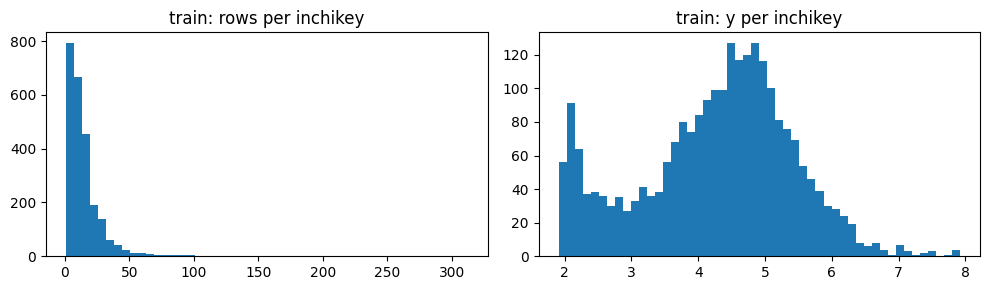

In [5]:
# Quick look: group-size distribution and target distribution (per inchikey)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(np.bincount(train_raw.codes), bins=50); ax[0].set_title('train: rows per inchikey')
y_grp = pd.Series(train_raw.y).groupby(train_raw.codes).first()
ax[1].hist(y_grp, bins=50); ax[1].set_title('train: y per inchikey')
plt.tight_layout(); plt.show()

## 3. Helpers

### 3.1 Group-balanced sampling
`balanced_indices(codes, n)` returns row indices with exactly `n` rows per group (groups larger than `n`
are subsampled without replacement; smaller groups are either kept as is or topped up with replacement).
Vectorised, so it is cheap to call every epoch even for millions of rows.

In [6]:
def balanced_indices(codes, n_per_group, rng, replace_small=True):
    codes = np.asarray(codes)
    order = np.lexsort((rng.random(len(codes)), codes))          # sort by group, random within group
    sc = codes[order]
    starts = np.r_[0, np.flatnonzero(np.diff(sc)) + 1]
    sizes = np.diff(np.r_[starts, len(sc)])
    rank = np.arange(len(sc)) - np.repeat(starts, sizes)        # position within the (shuffled) group
    idx = order[rank < n_per_group]
    if replace_small:
        short = np.maximum(n_per_group - sizes, 0)
        g = np.repeat(np.arange(len(sizes)), short)
        extra = order[starts[g] + rng.integers(0, sizes[g])]
        idx = np.concatenate([idx, extra])
    return rng.permutation(idx)


def group_weights(codes):
    # 1/group_size, normalised to mean 1 -> every inchikey has the same total weight
    w = 1.0 / np.bincount(codes)[codes]
    return w / w.mean()


def group_mean_split(s: Split):
    # one row per inchikey: mean embedding, the group's y
    df = pd.DataFrame(s.X); df['_g'] = s.codes
    Xm = df.groupby('_g').mean().to_numpy(np.float32)
    first = np.unique(s.codes, return_index=True)[1]
    return Split(Xm, s.y[first], s.numid[first], s.inchikey[first], np.arange(len(first)))


def split_by_group(s: Split, frac, seed=SEED):
    # carve out a fraction of inchikeys (e.g. an inner validation set for early stopping)
    rng = np.random.default_rng(seed)
    g = rng.permutation(s.n_groups)[: int(round(frac * s.n_groups))]
    m = np.isin(s.codes, g)
    return s.subset(np.flatnonzero(~m)), s.subset(np.flatnonzero(m))


# tiny self-test
_c = np.array([0]*10 + [1]*2 + [2]*1)
_i = balanced_indices(_c, 3, np.random.default_rng(0))
assert np.bincount(_c[_i]).tolist() == [3, 3, 3] and len(set(_i[_c[_i] == 0])) == 3
_i = balanced_indices(_c, 3, np.random.default_rng(0), replace_small=False)
assert np.bincount(_c[_i]).tolist() == [3, 2, 1]
print('balanced_indices OK')

balanced_indices OK


### 3.2 Preprocessing: StandardScaler → block-aware PCA
Fitted on **train only**, on a balanced subsample so that inchikeys with many rows do not dominate the components.

The embedding consists of 12 blocks (4 GNN layers × 3 poolings). They differ strongly: shallow blocks are low-rank and
largely repeat the same signal (e.g. `L1P1 ≈ L1P2`), deep blocks have much higher rank. A global PCA on the whole
vector therefore spends its top components on the signal repeated across shallow blocks. `PCA_MODE` chooses how to
reduce (all modes first standardise every feature; `BLOCK_SELECT` keeps a subset of blocks *before* everything else):

| `PCA_MODE` | what it does | output size |
|---|---|---|
| `'global'` | PCA on the whole (selected) vector - the previous behaviour | `PCA_DIM` |
| `'mfa'` | multiple factor analysis: every block is divided by √(its largest eigenvalue), so each block's main direction has the same weight, then one global PCA. Signals shared by several blocks are captured once, but no block dominates through repetition | `PCA_DIM` |
| `'blockwise'` | PCA inside every block, block-weighted the same way. `BLOCK_ALLOC='auto'`: the `PCA_DIM` components with the largest block-weighted variance over all blocks (low-rank blocks contribute few, high-rank blocks many); `'equal'`: `PCA_DIM // n_blocks` per block | `PCA_DIM` |

`PCA_DIM=None` → no PCA: standardisation only (`'global'`) or standardisation + block weights (`'mfa'`, `'blockwise'`).
`PCA_PROJECT_BACK=True` → the kept components are mapped back to the standardised (and block-weighted) original
coordinates: PCA acts as a denoiser while the model sees the original basis (Adam-trained heads are not
rotation-invariant). The output then has as many columns as the selected blocks.

Every model in section 7/8 can use its own settings (`with_pre`), e.g. TabICL with 256 components and a linear head
with the full vector.

In [7]:
def block_names(layers=None, pools=None):
    # block names in column order, optionally restricted, e.g. block_names(layers=(3, 4)) or block_names(pools=(3,))
    return [f'L{l}P{p}' for l in range(1, N_LAYERS + 1) for p in range(1, N_POOLS + 1)
            if (layers is None or l in layers) and (pools is None or p in pools)]


class EmbeddingReducer:
    # StandardScaler + block selection + 'global' / 'mfa' / 'blockwise' PCA (see the table above). fit(X) / transform(X)
    def __init__(self, pca_dim=256, mode='global', blocks=None, alloc='auto', project_back=False, whiten=False, seed=SEED):
        self.pca_dim, self.mode, self.blocks, self.alloc = pca_dim, mode, blocks, alloc
        self.project_back, self.whiten, self.seed = project_back, whiten, seed

    def fit(self, X):
        if self.mode not in ('global', 'mfa', 'blockwise'):
            raise ValueError(f'unknown PCA mode {self.mode!r}')
        names = block_names()
        if X.shape[1] % len(names):
            raise ValueError(f'{X.shape[1]} features cannot be split into {len(names)} equal blocks')
        bw = X.shape[1] // len(names)
        sel = list(names) if self.blocks is None else list(self.blocks)
        unknown = set(sel) - set(names)
        if unknown:
            raise ValueError(f'unknown blocks {sorted(unknown)}; valid: {names}')
        sel = [n for n in names if n in sel]                                   # keep column order
        self.sel_ = sel
        self.cols_ = np.concatenate([np.arange(names.index(n) * bw, (names.index(n) + 1) * bw) for n in sel])
        self.slices_ = [slice(i * bw, (i + 1) * bw) for i in range(len(sel))]  # block slices inside the selection
        self.scaler_ = StandardScaler().fit(X[:, self.cols_])
        Z = self.scaler_.transform(X[:, self.cols_])

        # per-block PCA (needed for the block weights of 'mfa'/'blockwise', and as the reducer of 'blockwise')
        self.w_ = np.ones(len(sel))
        if self.mode in ('mfa', 'blockwise'):
            self.bpca_ = [PCA(random_state=self.seed).fit(Z[:, s]) for s in self.slices_]
            self.w_ = np.array([1.0 / np.sqrt(p.explained_variance_[0]) for p in self.bpca_])
        Zw = self._weight(Z)
        k = self.pca_dim
        self.n_out_ = Z.shape[1]
        if k is None:
            return self
        if self.mode in ('global', 'mfa'):
            k = min(k, *Zw.shape)
            self.pca_ = PCA(n_components=k, whiten=self.whiten, random_state=self.seed,
                            svd_solver='randomized' if k < 0.5 * Zw.shape[1] else 'auto').fit(Zw)
            self.n_out_ = Zw.shape[1] if self.project_back else k
            return self
        # blockwise: choose which components of which block to keep
        rel = [p.explained_variance_ / p.explained_variance_[0] for p in self.bpca_]    # block-weighted variances
        if self.alloc == 'equal':
            per = [k // len(sel) + (i < k % len(sel)) for i in range(len(sel))]
            keep = [np.arange(min(n, len(r))) for n, r in zip(per, rel)]
        elif self.alloc == 'auto':
            allv = np.concatenate([r for r in rel])
            owner = np.concatenate([np.full(len(r), b) for b, r in enumerate(rel)])
            pos = np.concatenate([np.arange(len(r)) for r in rel])
            top = np.argsort(-allv, kind='stable')[:min(k, len(allv))]
            keep = [np.sort(pos[top][owner[top] == b]) for b in range(len(sel))]
        else:
            raise ValueError(f'unknown BLOCK_ALLOC {self.alloc!r}')
        self.keep_ = keep
        self.n_out_ = Z.shape[1] if self.project_back else int(sum(len(x) for x in keep))
        return self

    def _weight(self, Z):
        Z = Z.copy()
        for w, s in zip(self.w_, self.slices_):
            Z[:, s] *= w
        return Z

    def transform(self, X):
        Z = self.scaler_.transform(X[:, self.cols_])
        if self.pca_dim is None:
            return self._weight(Z)
        if self.mode in ('global', 'mfa'):
            S = self.pca_.transform(self._weight(Z))
            return self.pca_.inverse_transform(S) if self.project_back else S
        out = []
        for s, p, w, kk in zip(self.slices_, self.bpca_, self.w_, self.keep_):
            if len(kk) == 0:
                if self.project_back:
                    out.append(np.zeros((len(Z), s.stop - s.start)))
                continue
            S = (Z[:, s] - p.mean_) @ p.components_[kk].T                     # scores of the kept components
            if self.project_back:
                out.append((S @ p.components_[kk] + p.mean_) * w)              # back to (weighted) block coordinates
            elif self.whiten:
                out.append(S / np.sqrt(p.explained_variance_[kk]))
            else:
                out.append(S * w)
        return np.concatenate(out, axis=1)

    def summary(self):
        txt = f'{self.mode}: {len(self.cols_)} features ({len(self.sel_)} blocks) -> {self.n_out_}'
        if self.pca_dim is None:
            return txt + ' (no PCA)'
        if self.mode in ('global', 'mfa'):
            txt += f' | explained variance {self.pca_.explained_variance_ratio_.sum():.3f}'
        else:
            txt += ' | components per block: ' + ' '.join(f'{n}:{len(k)}' for n, k in zip(self.sel_, self.keep_))
        return txt + (' | projected back' if self.project_back else '')


def fit_preprocessor(s: Split, pca_dim=..., mode=..., blocks=..., alloc=..., project_back=..., whiten=...,
                     n_per_group=None, seed=SEED, verbose=True):
    # '...' (default) -> take the value from the config cell at call time; pca_dim=None means "no PCA"
    cfg = resolve_pre(dict(pca_dim=pca_dim, mode=mode, blocks=blocks, alloc=alloc, project_back=project_back,
                           whiten=whiten))
    rng = np.random.default_rng(seed)
    idx = balanced_indices(s.codes, n_per_group or PCA_FIT_N_PER_GROUP, rng, replace_small=False)
    pre = EmbeddingReducer(seed=seed, **cfg).fit(s.X[idx])
    if verbose:
        print(f'{pre.summary()} (fitted on {len(idx)} rows)')
    return pre


def resolve_pre(cfg=None):
    # fill unspecified ('...' or missing) preprocessing settings from the config cell
    defaults = dict(pca_dim=PCA_DIM, mode=PCA_MODE, blocks=BLOCK_SELECT, alloc=BLOCK_ALLOC,
                    project_back=PCA_PROJECT_BACK, whiten=PCA_WHITEN)
    cfg = {k: v for k, v in (cfg or {}).items() if v is not ...}
    unknown = set(cfg) - set(defaults)
    if unknown:
        raise ValueError(f'unknown preprocessing settings {sorted(unknown)}; valid: {sorted(defaults)}')
    return {**defaults, **cfg}


def transform(pre, s: Split, batch=200_000):
    X = np.concatenate([pre.transform(s.X[i:i + batch]) for i in range(0, len(s), batch)]).astype(np.float32)
    return s.with_X(X)


# self-test: 'global' must reproduce plain StandardScaler -> PCA
_idx = balanced_indices(train_raw.codes, PCA_FIT_N_PER_GROUP, np.random.default_rng(SEED), replace_small=False)
_k = 16
_old = make_pipeline(StandardScaler(), PCA(_k, random_state=SEED, svd_solver='randomized')).fit(train_raw.X[_idx])
_new = EmbeddingReducer(pca_dim=_k, mode='global').fit(train_raw.X[_idx])
assert np.allclose(_old.transform(train_raw.X[:100]), _new.transform(train_raw.X[:100]), atol=1e-3)
print('EmbeddingReducer OK')

pre = fit_preprocessor(train_raw)
train, val = transform(pre, train_raw), transform(pre, val_raw)
print('train', train.X.shape, '| val', val.X.shape)

EmbeddingReducer OK
global: 1344 features (12 blocks) -> 256 | explained variance 0.997 (fitted on 16659 rows)
train (36347, 256) | val (2657, 256)


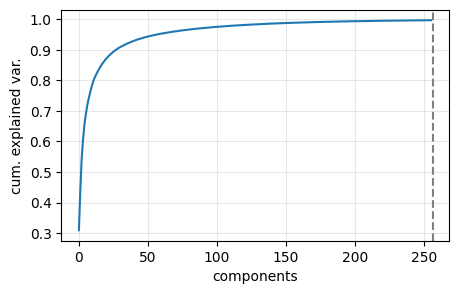

In [8]:
# Explained-variance curve (helps to choose PCA_DIM). Fits a bigger PCA once on a balanced subsample.
_idx = balanced_indices(train_raw.codes, PCA_FIT_N_PER_GROUP, np.random.default_rng(SEED), replace_small=False)
_k = min(256, len(_idx), train_raw.X.shape[1])
_p = make_pipeline(StandardScaler(), PCA(n_components=_k, random_state=SEED)).fit(train_raw.X[_idx])
plt.figure(figsize=(5, 3)); plt.plot(np.cumsum(_p[-1].explained_variance_ratio_))
plt.axvline(PCA_DIM or 0, ls='--', c='gray'); plt.xlabel('components'); plt.ylabel('cum. explained var.')
plt.grid(alpha=.3); plt.show()

#### Block diagnostics (exploration variant)
Per block: raw scale, effective rank (components for 95 % of its variance), how much of the top global-PCA variance it
supplies, and how predictive it is on its own (group-weighted ridge; `alpha` chosen on held-out *train* inchikeys,
scored on val). Also per layer (its 3 poolings) and per pooling (its 4 layers). Helps to choose `BLOCK_SELECT`.
On small val sets differences of ~0.01 MAE are noise.

In [9]:
RUN_BLOCK_DIAGNOSTICS = False

if RUN_BLOCK_DIAGNOSTICS:
    from sklearn.linear_model import Ridge
    _names = block_names(); _bw = train_raw.X.shape[1] // len(_names)
    _cols = {n: np.arange(i * _bw, (i + 1) * _bw) for i, n in enumerate(_names)}
    _idx = balanced_indices(train_raw.codes, PCA_FIT_N_PER_GROUP, np.random.default_rng(SEED), replace_small=False)
    _fit, _hold = split_by_group(train_raw, 0.2, SEED)

    def _ridge_val_mae(cols, alphas=(1, 10, 100, 1e3, 1e4, 1e5)):
        sc = StandardScaler().fit(train_raw.X[_idx][:, cols])
        def fit(s, a):
            return Ridge(alpha=a).fit(sc.transform(s.X[:, cols]), s.y, sample_weight=group_weights(s.codes))
        def gmae(model, s):
            p = model.predict(sc.transform(s.X[:, cols]))
            d = pd.DataFrame({'g': s.codes, 'y': s.y, 'p': p}).groupby('g').mean()
            return float((d.y - d.p).abs().mean())
        a = min(alphas, key=lambda a: gmae(fit(_fit, a), _hold))          # alpha chosen without val
        return gmae(fit(train_raw, a), val_raw), a

    _Z = StandardScaler().fit_transform(train_raw.X[_idx])
    _gp = PCA(32, random_state=SEED).fit(_Z)
    _ld = _gp.components_ ** 2 * _gp.explained_variance_[:, None]
    rows = []
    for n, c in _cols.items():
        x = train_raw.X[_idx][:, c]
        ev = PCA(random_state=SEED).fit(StandardScaler().fit_transform(x)).explained_variance_ratio_
        mae, a = _ridge_val_mae(c)
        rows.append(dict(block=n, raw_std=float(x.std(0).mean()), comps_95pct=int(np.searchsorted(np.cumsum(ev), .95) + 1),
                         share_top8_global_PCs=float(_ld[:8][:, c].sum() / _ld[:8].sum()),
                         share_top32_global_PCs=float(_ld[:, c].sum() / _ld.sum()), ridge_val_mae=mae, alpha=a))
    display(pd.DataFrame(rows).set_index('block').round(3))
    grp = {**{f'layer {l} (3 pools)': block_names(layers=(l,)) for l in range(1, N_LAYERS + 1)},
           **{f'pool {p} (4 layers)': block_names(pools=(p,)) for p in range(1, N_POOLS + 1)},
           'all blocks': _names}
    display(pd.DataFrame({k: _ridge_val_mae(np.concatenate([_cols[n] for n in v])) for k, v in grp.items()},
                         index=['ridge_val_mae', 'alpha']).T.round(4))

### 3.3 Evaluation
`evaluate(name, numid, y_pred)` joins predictions back to val rows **by `numid`**, saves the raw table,
groups by `inchikey` (mean/median/std of row predictions) and computes metrics on the grouped table.
Each call appends a line to `RESULTS` and writes into `OUT_DIR/<name>/`.

In [10]:
RESULTS = []
VAL_META = pd.DataFrame({'numid': val_raw.numid, 'inchikey': val_raw.inchikey, 'y_true': val_raw.y})


def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return dict(rmse=float(np.sqrt(mean_squared_error(y_true, y_pred))),
                mae=float(mean_absolute_error(y_true, y_pred)),
                r2=float(r2_score(y_true, y_pred)),
                pearson=float(stats.pearsonr(y_true, y_pred)[0]) if y_pred.std() > 0 else np.nan,
                spearman=float(stats.spearmanr(y_true, y_pred)[0]) if y_pred.std() > 0 else np.nan)


def group_predictions(raw):
    return (raw.groupby('inchikey')
               .agg(y_true=('y_true', 'first'), y_pred=('y_pred', 'mean'),
                    y_pred_median=('y_pred', 'median'), y_pred_std=('y_pred', 'std'),
                    n_rows=('y_pred', 'size'))
               .reset_index())


def evaluate(name, numid, y_pred, params=None, meta=None, save=True, verbose=True):
    # meta: DataFrame(numid, inchikey, y_true) of the evaluated split; default = the exploration val split
    meta = VAL_META if meta is None else meta
    pred = pd.DataFrame({'numid': np.asarray(numid, np.int64), 'y_pred': np.asarray(y_pred, float).ravel()})
    assert pred['numid'].is_unique, 'duplicate numids in predictions'
    raw = meta.merge(pred, on='numid', how='left', validate='one_to_one')
    if raw['y_pred'].isna().any():
        raise ValueError(f"{raw['y_pred'].isna().sum()} val rows have no prediction")
    return report(name, group_predictions(raw), raw, params, save, verbose)


def report(name, grp, raw=None, params=None, save=True, verbose=True):
    # metrics on a grouped table (inchikey, y_true, y_pred[, y_pred_median]); raw (per-row) is optional
    m = regression_metrics(grp['y_true'], grp['y_pred'])                       # main: grouped, mean-aggregated
    if 'y_pred_median' in grp:
        m |= {f'{k}_median_agg': v for k, v in regression_metrics(grp['y_true'], grp['y_pred_median']).items()
              if k in ('rmse', 'r2')}
    if raw is not None:
        m |= {f'{k}_rows': v for k, v in regression_metrics(raw['y_true'], raw['y_pred']).items()
              if k in ('rmse', 'r2')}                                          # per-row, for reference only
    row = dict(run=RUN_TAG, model=name, **m, time=time.strftime('%Y-%m-%d %H:%M'),
               params=json.dumps(params or {}, default=str))
    RESULTS.append(row)

    if save:
        d = OUT_DIR / name; d.mkdir(parents=True, exist_ok=True)
        if raw is not None:
            raw.to_csv(d / 'val_predictions_raw.csv', index=False)
        grp.to_csv(d / 'val_predictions_grouped.csv', index=False)
        (d / 'metrics.json').write_text(json.dumps(row, indent=2))
    if verbose:
        rows = f"   | rows: RMSE {m['rmse_rows']:.4f}" if 'rmse_rows' in m else ''
        print(f"[{name}] grouped: RMSE {m['rmse']:.4f}  MAE {m['mae']:.4f}  R2 {m['r2']:.4f}  "
              f"Spearman {m['spearman']:.4f}{rows}")
    return grp


# sanity check: predicting the train mean must give R2 <= 0
_ = evaluate('_dummy_mean', val.numid, np.full(len(val), train.y.mean()), save=False)
RESULTS.clear()

[_dummy_mean] grouped: RMSE 1.0535  MAE 0.8785  R2 -0.0299  Spearman nan   | rows: RMSE 1.0733


## 4. Models

### 4.1 sklearn-style models (and anything with `.fit(X, y)` / `.predict(X)`)

`fit_predict(make_model, train, val, mode=...)`:
* `'all'` – plain fit on all rows (unbalanced baseline)
* `'weight'` – `sample_weight = 1/group_size` (RF, ExtraTrees, HistGB, Ridge, SVR, XGBoost/LightGBM … support it; KNN does not)
* `'bag'` – `n_bags` models, each fitted on its own balanced draw of `n_per_group` rows per inchikey, predictions averaged.
  This is the closest analogue of per-epoch resampling. For a random forest, `n_bags × n_estimators` trees in total,
  i.e. a "group-balanced random forest". `max_rows` caps the size of each draw (useful for TabICL/KNN).
* `'group_mean'` – one averaged embedding per inchikey (fast, often a strong baseline)

In [11]:
# DEFINITIONS - GPU memory housekeeping
import gc, sys

GPU_MEM_VERBOSE = True     # print VRAM after every fit: 'allocated' should stay flat from fit to fit


def free_gpu(tag=''):
    # 1) forget the last exception: after an OOM the notebook keeps its traceback, i.e. the frames of the failed
    #    cell and every GPU tensor they reference; 2) collect unreachable objects; 3) hand cached blocks back to
    #    the driver (also makes TabICL's offload_mode='auto' see the true free memory).
    sys.last_type = sys.last_value = sys.last_traceback = None
    if hasattr(sys, 'last_exc'):
        sys.last_exc = None
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()
        if GPU_MEM_VERBOSE and tag:
            gb = 2 ** 30
            free, total = torch.cuda.mem_get_info()
            print(f'  [gpu after {tag}] allocated {torch.cuda.memory_allocated() / gb:.2f} GB | '
                  f'reserved {torch.cuda.memory_reserved() / gb:.2f} GB | '
                  f'peak since last report {torch.cuda.max_memory_allocated() / gb:.2f} GB | '
                  f'free {free / gb:.2f} of {total / gb:.1f} GB')
        torch.cuda.reset_peak_memory_stats()


In [12]:
# DEFINITIONS
def predict_chunked(model, X, chunk=50_000):
    return np.concatenate([np.asarray(model.predict(X[i:i + chunk])).ravel() for i in range(0, len(X), chunk)])


def fit_predict(make_model, train: Split, val, mode='weight', n_bags=5, n_per_group=N_PER_GROUP,
                replace_small=REPLACE_SMALL, max_rows=None, seed=SEED, pred_chunk=50_000):
    # make_model: zero-arg callable returning a fresh unfitted model, e.g. lambda: Ridge(alpha=1.0)
    # val: one Split -> returns one array; a list of Splits -> returns a list of arrays (one fit, several predictions)
    sets = list(val) if isinstance(val, (list, tuple)) else [val]
    rng = np.random.default_rng(seed)
    t0 = time.time()
    predict_all = lambda model: [predict_chunked(model, v.X, pred_chunk) for v in sets]
    if mode == 'all':
        model = make_model().fit(train.X, train.y)
        pred = predict_all(model)
        del model; free_gpu(mode)
    elif mode == 'weight':
        model = make_model().fit(train.X, train.y, sample_weight=group_weights(train.codes))
        pred = predict_all(model)
        del model; free_gpu(mode)
    elif mode == 'group_mean':
        tm = group_mean_split(train)
        model = make_model().fit(tm.X, tm.y)
        pred = predict_all(model)
        del model, tm; free_gpu(mode)
    elif mode == 'bag':
        preds = []
        for b in range(n_bags):
            idx = balanced_indices(train.codes, n_per_group, rng, replace_small=replace_small)
            if max_rows is not None and len(idx) > max_rows:
                idx = rng.choice(idx, max_rows, replace=False)
            model = make_model()
            if 'random_state' in model.get_params():
                model.set_params(random_state=seed + b)       # different trees in every bag
            model.fit(train.X[idx], train.y[idx])
            preds.append(predict_all(model))
            del model
            print(f'  bag {b + 1}/{n_bags}: {len(idx)} rows, {time.time() - t0:.0f}s')
            free_gpu(f'bag {b + 1}')
        pred = [np.mean([p[j] for p in preds], axis=0) for j in range(len(sets))]
    else:
        raise ValueError(mode)
    print(f'  fit+predict {time.time() - t0:.1f}s')
    return pred if isinstance(val, (list, tuple)) else pred[0]


def run(name, make_model, mode='weight', **kw):
    pred = fit_predict(make_model, train, val, mode=mode, **kw)
    params = {'mode': mode, **kw, 'model': repr(make_model()), 'pca_dim': PCA_DIM}
    evaluate(name, val.numid, pred, params=params)
    return pred

### 4.3 MLP (PyTorch)
* `BalancedGroupSampler` draws a fresh balanced set of row indices **every epoch**.
* The dataset returns `(x, y, numid)`; `numid` travels through the `DataLoader` and is used to join predictions back.
* Target is standardised internally; early stopping on the **grouped** RMSE.
  `es_on='val'` uses the validation set (convenient, but then the val score is optimistically biased);
  `es_on='inner'` carves `inner_frac` of train inchikeys out for early stopping instead.

In [13]:
# DEFINITIONS
class RowDataset(Dataset):
    def __init__(self, s: Split, y_mean=0.0, y_std=1.0):
        self.X = torch.from_numpy(s.X)
        self.y = torch.from_numpy((s.y - y_mean) / y_std).float()
        self.numid = torch.as_tensor(np.array(s.numid, np.int64))

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        # i is a whole batch of indices (we use a BatchSampler) -> one vectorised gather instead of 256 calls
        i = torch.as_tensor(i)
        return self.X[i], self.y[i], self.numid[i]


def make_loader(ds, sampler, batch_size, drop_last=False, generator=None):
    # batch_size=None + BatchSampler -> __getitem__ receives the list of indices of a batch
    return DataLoader(ds, sampler=torch.utils.data.BatchSampler(sampler, batch_size, drop_last), batch_size=None,
                      generator=generator)


class BalancedGroupSampler(Sampler):
    # new balanced draw on every iteration (= every epoch)
    def __init__(self, codes, n_per_group, replace_small=True, seed=SEED):
        self.codes, self.n, self.replace_small = np.asarray(codes), n_per_group, replace_small
        self.rng = np.random.default_rng(seed)
        self._len = len(balanced_indices(self.codes, self.n, self.rng, self.replace_small))

    def __iter__(self):
        return iter(balanced_indices(self.codes, self.n, self.rng, self.replace_small).tolist())

    def __len__(self):
        return self._len


class MLP(nn.Module):
    def __init__(self, d_in, hidden=(512, 256, 128), dropout=0.5, norm='None', act=nn.GELU):
        super().__init__()
        layers, d = [], d_in
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if norm == 'layer':
                layers.append(nn.LayerNorm(h))
            elif norm == 'batch':
                layers.append(nn.BatchNorm1d(h))
            layers += [act(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


@torch.no_grad()
def mlp_predict(model, s: Split, y_mean, y_std, batch_size=4096):
    model.eval()
    dl = make_loader(RowDataset(s), torch.utils.data.SequentialSampler(range(len(s))), batch_size,
                     generator=torch.Generator())     # own RNG: scoring must not shift the training randomness
    preds, ids = [], []
    for xb, _, nb in dl:
        preds.append(model(xb.to(DEVICE)).float().cpu().numpy())
        ids.append(nb.numpy())
    return np.concatenate(ids), np.concatenate(preds) * y_std + y_mean


def grouped_rmse(s: Split, numid, pred):
    p = pd.Series(pred, index=numid).reindex(s.numid).to_numpy()   # align by numid
    df = pd.DataFrame({'g': s.codes, 'y': s.y, 'p': p}).groupby('g').agg(y=('y', 'first'), p=('p', 'mean'))
    return float(np.sqrt(((df.y - df.p) ** 2).mean()))


def make_scheduler(opt, schedule, epochs, steps_per_epoch, t_max=None, const_epochs=None, decay_frac=0.15):
    # Learning-rate schedule, stepped after EVERY optimiser step. Returns (scheduler or None, total optimiser steps).
    #   'cosine'         : cosine annealing over t_max epochs (default t_max = epochs), i.e. t_max * steps_per_epoch steps
    #   'constant'       : constant lr (natural for early-stopped fits: the horizon is unknown)
    #   'constant_decay' : constant lr, then linear decay to ~0 -
    #       const_epochs=None: the decay is the last decay_frac of the `epochs` budget;
    #       const_epochs=N   : N epochs at constant lr, then decay_frac * N epochs of decay APPENDED (may end mid-epoch)
    spe = max(1, int(steps_per_epoch))
    if schedule == 'cosine':
        return torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=(t_max or epochs) * spe), epochs * spe
    if schedule == 'constant':
        return None, epochs * spe
    if schedule == 'constant_decay':
        if const_epochs is None:
            total = epochs * spe
            n_dec = max(1, int(round(decay_frac * total)))
            n_const = total - n_dec
        else:
            n_const = int(const_epochs) * spe
            n_dec = max(1, int(round(decay_frac * n_const)))
            total = n_const + n_dec
        lam = lambda s: 1.0 if s < n_const else max(0.0, (total - s) / n_dec)   # s = optimiser steps done so far
        return torch.optim.lr_scheduler.LambdaLR(opt, lam), total
    raise ValueError(f'unknown schedule {schedule!r}')


def train_mlp(train: Split, val: Split, hidden=(512, 256, 128), dropout=0.5, norm='None',
              lr=1e-3, weight_decay=1e-4, bias_decay=1e-4, batch_size=256, epochs=200, patience=20,
              n_per_group=N_PER_GROUP, replace_small=REPLACE_SMALL, loss='mse', huber_delta=1.0,
              es_on='val', inner_frac=0.1, seed=SEED, verbose_every=10,
              schedule='cosine', t_max=None, const_epochs=None, decay_frac=0.15):
    # es_on: 'val' (early stopping on `val`), 'inner' (on inner_frac of train inchikeys),
    #        'none' (fixed number of epochs, last state kept - e.g. for a refit with a known epoch count)
    # schedule / t_max / decay_epochs / decay_frac: see make_scheduler. model.best_epoch = epoch of the kept weights.
    torch.manual_seed(seed)
    if es_on == 'inner':
        fit_s, es_s = split_by_group(train, inner_frac, seed)
    elif es_on == 'val':
        if val is None:
            raise ValueError("es_on='val' needs a validation split; use 'inner' or 'none' (e.g. for refits)")
        fit_s, es_s = train, val
    elif es_on == 'none':
        fit_s, es_s = train, None
    else:
        raise ValueError(es_on)

    y_mean, y_std = float(fit_s.y.mean()), float(fit_s.y.std())
    sampler = BalancedGroupSampler(fit_s.codes, n_per_group, replace_small, seed)
    dl = make_loader(RowDataset(fit_s, y_mean, y_std), sampler, batch_size, drop_last=len(sampler) > batch_size)

    model = MLP(fit_s.X.shape[1], hidden, dropout, norm).to(DEVICE)
    bias_params = [p for name, p in model.named_parameters() if 'bias' in name]
    weight_params = [p for name, p in model.named_parameters() if 'bias' not in name]
    opt = torch.optim.AdamW([{'params': weight_params, 'weight_decay': weight_decay, 'lr': lr},
                             {'params': bias_params,   'weight_decay': bias_decay,   'lr': lr}])
    sched, total_steps = make_scheduler(opt, schedule, epochs, len(dl), t_max, const_epochs, decay_frac)
    epochs = max(epochs, -(-total_steps // len(dl)))          # appended decay may need part of one more epoch
    crit = nn.MSELoss() if loss == 'mse' else nn.HuberLoss(delta=huber_delta)

    best, best_state, bad, hist, best_ep, step = np.inf, None, 0, [], None, 0
    for ep in range(1, epochs + 1):
        model.train(); tot, n = 0.0, 0
        for xb, yb, _ in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            l = crit(model(xb), yb)
            l.backward(); opt.step()
            if sched is not None:
                sched.step()                                  # per optimiser step
            step += 1
            tot += l.item() * len(yb); n += len(yb)
            if step >= total_steps:
                break
        if es_s is None:
            es_rmse = np.nan
        else:
            ids, p = mlp_predict(model, es_s, y_mean, y_std)
            es_rmse = grouped_rmse(es_s, ids, p)
        hist.append((ep, tot / n, es_rmse))
        if es_s is None:
            pass
        elif es_rmse < best - 1e-5:
            best, best_state, bad, best_ep = es_rmse, copy.deepcopy(model.state_dict()), 0, ep
        else:
            bad += 1
        if verbose_every and (ep % verbose_every == 0 or ep == 1):
            print(f'  ep {ep:4d}  train_loss {tot / n:.4f}  {es_on}_grouped_rmse {es_rmse:.4f}  best {best:.4f}')
        if bad >= patience:
            print(f'  early stop at epoch {ep} (best {best:.4f})'); break
        if step >= total_steps:
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    model.y_mean, model.y_std = y_mean, y_std
    model.best_epoch = best_ep if best_ep is not None else len(hist)     # es_on='none': the last epoch
    return model, pd.DataFrame(hist, columns=['epoch', 'train_loss', 'es_grouped_rmse'])


def run_mlp(name, **kw):
    t0 = time.time()
    model, hist = train_mlp(train, val, **kw)
    ids, pred = mlp_predict(model, val, model.y_mean, model.y_std)
    print(f'  {time.time() - t0:.0f}s')
    evaluate(name, ids, pred, params={**kw, 'pca_dim': PCA_DIM, 'n_per_group': kw.get('n_per_group', N_PER_GROUP)})
    hist.to_csv(OUT_DIR / name / 'history.csv', index=False)
    return model, hist

#### MLP deep ensemble
Same architecture trained with different seeds (different init, different balanced draws each epoch and, with
`es_on='inner'`, a different inner early-stopping split per member); predictions averaged. Usually the cheapest
reliable gain for neural nets.

In [14]:
# DEFINITIONS
def run_mlp_ensemble(name, seeds=(0, 1, 2, 3, 4), **kw):
    preds = []
    for sd in seeds:
        model, hist = train_mlp(train, val, seed=sd, verbose_every=0, **kw)
        ids, p = mlp_predict(model, val, model.y_mean, model.y_std)
        preds.append(pd.Series(p, index=ids))
        print(f'  member seed={sd}: stopped at epoch {len(hist)}')
    P = pd.concat(preds, axis=1)
    evaluate(name, P.index.to_numpy(), P.mean(axis=1).to_numpy(), params={**kw, 'seeds': list(seeds), 'pca_dim': PCA_DIM})
    return P


### 4.4 Set model (DeepSets with attention pooling) – one prediction per inchikey
Since the target belongs to the inchikey, not to the individual entity, a natural model takes the **whole bag of
rows of an inchikey** as input: a shared network φ embeds every row, rows are pooled (attention-weighted or plain mean),
and a head ρ predicts `y`.
* Training: each epoch every inchikey is one sample, represented by `k` rows drawn from it (with replacement) →
  balanced by construction.
* Inference: all rows of an inchikey are used (padding + mask; `eval_max_k` caps very large groups).
* The model outputs one value per inchikey; for the raw file that value is copied to all rows of the inchikey.

In [15]:
# DEFINITIONS
class GroupBags:
    # row indices of every inchikey as contiguous slices of `order`; group g == code g
    def __init__(self, s: Split):
        self.order = np.argsort(s.codes, kind='stable')
        sc = s.codes[self.order]
        self.starts = np.r_[0, np.flatnonzero(np.diff(sc)) + 1]
        self.sizes = np.diff(np.r_[self.starts, len(sc)])
        first = self.order[self.starts]
        self.y, self.inchikey = s.y[first], s.inchikey[first]
        self.X = torch.from_numpy(s.X)
        self.G = len(self.starts)

    def sample(self, g, k, rng):
        # k rows per group, with replacement -> (B, k, d), mask all True
        pos = self.starts[g][:, None] + (rng.random((len(g), k)) * self.sizes[g][:, None]).astype(np.int64)
        return self.X[torch.from_numpy(self.order[pos])], torch.ones(len(g), k, dtype=torch.bool)

    def all_rows(self, g, max_k=None):
        # all rows of each group, padded to the largest group in the batch -> (B, K, d), mask
        sz = self.sizes[g] if max_k is None else np.minimum(self.sizes[g], max_k)
        ar = np.arange(sz.max())
        mask = ar[None, :] < sz[:, None]
        pos = self.starts[g][:, None] + np.minimum(ar[None, :], sz[:, None] - 1)
        return self.X[torch.from_numpy(self.order[pos])], torch.from_numpy(mask)


# self-test: padded "all rows" view must contain every val row exactly once, in group order
_b = GroupBags(val); _x, _m = _b.all_rows(np.arange(_b.G))
assert int(_m.sum()) == len(val) and torch.equal(_x[_m], _b.X[torch.from_numpy(_b.order)])
assert (_b.y == pd.Series(val.y).groupby(val.codes).first().to_numpy()).all()
print('GroupBags OK')


def ff_layers(d_in, hidden, dropout):
    layers, d = [], d_in
    for h in hidden:
        layers += [nn.Linear(d, h), nn.LayerNorm(h), nn.GELU(), nn.Dropout(dropout)]
        d = h
    return nn.Sequential(*layers), d


class SetRegressor(nn.Module):
    def __init__(self, d_in, phi=(256, 128), head=(128,), dropout=0.5, pool='attn'):
        super().__init__()
        self.phi, d = ff_layers(d_in, phi, dropout)
        self.pool = pool
        if pool == 'attn':
            self.att = nn.Sequential(nn.Linear(d, 64), nn.Tanh(), nn.Linear(64, 1))
        self.rho, d2 = ff_layers(d, head, dropout)
        self.out = nn.Linear(d2, 1)

    def forward(self, x, mask):
        h = self.phi(x)                                               # (B, K, d)
        if self.pool == 'attn':
            a = self.att(h).squeeze(-1).masked_fill(~mask, float('-inf'))
            w = torch.softmax(a, dim=1)
        else:
            w = mask.float() / mask.sum(1, keepdim=True)
        z = (w.unsqueeze(-1) * h).sum(1)                              # (B, d)
        return self.out(self.rho(z)).squeeze(-1)


@torch.no_grad()
def set_predict(model, bags: GroupBags, y_mean, y_std, batch_groups=256, max_k=None):
    model.eval(); out = []
    for i in range(0, bags.G, batch_groups):
        x, m = bags.all_rows(np.arange(i, min(i + batch_groups, bags.G)), max_k)
        out.append(model(x.to(DEVICE), m.to(DEVICE)).float().cpu().numpy())
    return np.concatenate(out) * y_std + y_mean                       # one value per group (code order)


def train_set_model(train: Split, val: Split, k=8, phi=(256, 128), head=(128,), dropout=0.5, pool='attn',
                    lr=1e-3, weight_decay=1e-4, batch_groups=64, epochs=200, patience=20, loss='mse',
                    es_on='val', inner_frac=0.1, eval_max_k=None, seed=SEED, verbose_every=10,
                    schedule='cosine', t_max=None, const_epochs=None, decay_frac=0.15):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    if es_on == 'inner':
        fit_s, es_s = split_by_group(train, inner_frac, seed)
    elif es_on == 'val':
        if val is None:
            raise ValueError("es_on='val' needs a validation split; use 'inner' or 'none' (e.g. for refits)")
        fit_s, es_s = train, val
    elif es_on == 'none':
        fit_s, es_s = train, None
    else:
        raise ValueError(es_on)
    tb = GroupBags(fit_s)
    eb = GroupBags(es_s) if es_s is not None else None
    y_mean, y_std = float(tb.y.mean()), float(tb.y.std())
    yt = torch.from_numpy((tb.y - y_mean) / y_std).float()

    model = SetRegressor(fit_s.X.shape[1], phi, head, dropout, pool).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    spe = tb.G // batch_groups + (tb.G % batch_groups >= 2)   # optimiser steps per epoch (1-group tail is skipped)
    sched, total_steps = make_scheduler(opt, schedule, epochs, spe, t_max, const_epochs, decay_frac)
    epochs = max(epochs, -(-total_steps // spe))              # appended decay may need part of one more epoch
    crit = nn.MSELoss() if loss == 'mse' else nn.HuberLoss(delta=1.0)

    best, best_state, bad, hist, best_ep, step = np.inf, None, 0, [], None, 0
    for ep in range(1, epochs + 1):
        model.train(); tot = 0.0
        perm = rng.permutation(tb.G)
        for i in range(0, tb.G, batch_groups):
            g = perm[i:i + batch_groups]
            if len(g) < 2: continue
            x, m = tb.sample(g, k, rng)
            opt.zero_grad(set_to_none=True)
            l = crit(model(x.to(DEVICE), m.to(DEVICE)), yt[g].to(DEVICE))
            l.backward(); opt.step()
            if sched is not None:
                sched.step()                                  # per optimiser step
            step += 1
            tot += l.item() * len(g)
            if step >= total_steps:
                break
        if eb is None:
            es_rmse = np.nan
        else:
            p = set_predict(model, eb, y_mean, y_std, max_k=eval_max_k)
            es_rmse = float(np.sqrt(np.mean((p - eb.y) ** 2)))
        hist.append((ep, tot / tb.G, es_rmse))
        if eb is None:
            pass
        elif es_rmse < best - 1e-5:
            best, best_state, bad, best_ep = es_rmse, copy.deepcopy(model.state_dict()), 0, ep
        else:
            bad += 1
        if verbose_every and (ep % verbose_every == 0 or ep == 1):
            print(f'  ep {ep:4d}  train_loss {tot / tb.G:.4f}  {es_on}_grouped_rmse {es_rmse:.4f}  best {best:.4f}')
        if bad >= patience:
            print(f'  early stop at epoch {ep} (best {best:.4f})'); break
        if step >= total_steps:
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    model.y_mean, model.y_std = y_mean, y_std
    model.best_epoch = best_ep if best_ep is not None else len(hist)     # es_on='none': the last epoch
    return model, pd.DataFrame(hist, columns=['epoch', 'train_loss', 'es_grouped_rmse'])


def run_set(name, eval_max_k=None, **kw):
    t0 = time.time()
    model, hist = train_set_model(train, val, eval_max_k=eval_max_k, **kw)
    g_pred = set_predict(model, GroupBags(val), model.y_mean, model.y_std, max_k=eval_max_k)
    print(f'  {time.time() - t0:.0f}s')
    evaluate(name, val.numid, g_pred[val.codes], params={**kw, 'pca_dim': PCA_DIM})   # group value -> its rows
    hist.to_csv(OUT_DIR / name / 'history.csv', index=False)
    return model, hist

GroupBags OK


## 7. Multi-variant validation

**Model specs.** To run the same model on many variants (and later refit it), each model is written down once as a
*spec*: a function `spec(train, [split1, split2, ...], es_split=None) -> [pred1, pred2, ...]` that fits on `train`
and predicts every split. Helpers build specs from what is defined above:
* `sk_spec(make_model, mode=..., **kw)` – any sklearn-style model (incl. TabICL, LightGBM, …) with the balancing modes of 4.1
* `mlp_spec(**kw)` / `mlp_ens_spec(seeds, **kw)` – MLP / MLP deep ensemble (kwargs of `train_mlp`)
* `set_spec(**kw)` – set model (kwargs of `train_set_model`)

**Epochs of the neural specs** (`mlp_spec`, `mlp_ens_spec`, `set_spec`). In section 7 every early-stopped fit records
the epoch of its best score per model / variant / seed (`BEST_EPOCHS`, saved to `OUT_DIR/best_epochs.json`). In the
section-8 refit there is no validation split, so by default (`refit='replay'`) each fit trains exactly that many epochs
without early stopping - this works for `es_on='val'` as well as `es_on='inner'`:
* `refit_schedule='same'` (default): the validated learning-rate path up to the recorded epoch (cosine keeps its
  original horizon, so the replay sees the same learning rates as the validated fit);
* `refit_schedule='constant_decay'`: the recorded number of epochs at constant lr, then `refit_decay_frac` (15 %) of
  that budget, counted in optimiser steps, as linear decay to ~0 (may end mid-epoch) - meant for validation fits with
  `schedule='constant'`;
* `refit_epoch_scale` multiplies the recorded epochs (e.g. 1.1 for the larger train+val set); `refit='es'` keeps
  early stopping in the refit (`es_on='inner'` only).

Learning-rate schedules (`schedule=` in the spec kwargs; all are updated after every optimiser step, not per epoch):
`'cosine'` (default, horizon = `epochs`), `'constant'`, `'constant_decay'` (last `decay_frac` of the steps decay linearly).

**Per-model preprocessing.** `with_pre(spec, pca_dim=..., mode=..., blocks=..., alloc=..., project_back=..., whiten=...)`
gives a model its own preprocessing; anything not given comes from the config cell. Within a variant one preprocessor
is fitted per *distinct* setting and shared by all models that use it (`PrepCache`), e.g.
`'tabicl_bag': with_pre(sk_spec(...), pca_dim=256, mode='mfa')`, `'mlp_0x_ens5': with_pre(mlp_ens_spec(...), pca_dim=None)`.

**Loop.** For every variant: load → fit scaler/PCA (one per distinct preprocessing setting) on that variant's train → fit every spec → evaluate on val
(`<model>__v<variant>`). Then per model the grouped predictions are averaged over variants (`<model>__vavg`), and the
variant-averaged models are ensembled (`ens_mean__vavg`, `ens_nnls_cv__vavg`).
Averaging is done **per inchikey**, so it works even if the variants do not share `numid`s.

In [16]:
# DEFINITIONS - model specs

from scipy.optimize import nnls

def sk_spec(make_model, mode='weight', **kw):
    return lambda tr, sets, es_split=None: fit_predict(make_model, tr, list(sets), mode=mode, **kw)


# ---- best-epoch recording (section 7) and replay (section 8 refit) for the neural specs ----------------
RUN_CTX = {}                                    # set by the loops: model name, variant, phase ('val' | 'refit')
BEST_EPOCHS = {}                                # 'model|variant|seed' -> epoch of the best early-stopping score
BEST_EPOCHS_FILE = OUT_DIR / 'best_epochs.json' # persisted, so the refit also works after a kernel restart


def _epoch_key(seed):
    return f"{RUN_CTX.get('model')}|{RUN_CTX.get('variant')}|{seed}"


def record_best_epoch(seed, epoch):
    if RUN_CTX.get('phase') != 'val' or 'model' not in RUN_CTX:
        return
    BEST_EPOCHS[_epoch_key(seed)] = int(epoch)
    BEST_EPOCHS_FILE.write_text(json.dumps(BEST_EPOCHS, indent=1))


def recorded_best_epoch(seed):
    if BEST_EPOCHS_FILE.exists():
        BEST_EPOCHS.update({k: v for k, v in json.loads(BEST_EPOCHS_FILE.read_text()).items() if k not in BEST_EPOCHS})
    key = _epoch_key(seed)
    if key in BEST_EPOCHS:
        return BEST_EPOCHS[key], 'recorded'
    same = [e for k, e in BEST_EPOCHS.items() if k.split('|')[0] == RUN_CTX.get('model')]
    if same:                                    # e.g. a variant / seed that was not validated
        return int(np.median(same)), f'median of {len(same)} recorded fits of this model; none for {key}'
    raise KeyError(f'no recorded best epoch for {key} - run this model in section 7 first (or use refit="es")')


def refit_kwargs(kw, seed, refit, refit_schedule, refit_decay_frac, refit_epoch_scale):
    # Training kwargs for the section-8 refit (no validation split there).
    #   refit='replay': train exactly N epochs without early stopping, N = best epoch recorded in section 7
    #                   for the same model / variant / seed (x refit_epoch_scale), then
    #                   refit_schedule='same'          : the validated lr path up to epoch N (cosine keeps its horizon)
    #                   refit_schedule='constant_decay': N epochs at constant lr + refit_decay_frac * N epochs
    #                                                    worth of optimiser steps of linear decay to ~0
    #   refit='es'    : early stopping as in validation (only possible with es_on='inner')
    es_on = kw.get('es_on', 'val')
    if es_on == 'none':
        return kw, 'fixed epochs (es_on="none")'
    if refit == 'es':
        if es_on == 'val':
            raise ValueError("es_on='val' cannot early-stop in the refit (no validation split); use refit='replay'")
        return kw, f'early stopping ({es_on})'
    n, how = recorded_best_epoch(seed)
    n = max(1, int(round(n * refit_epoch_scale)))
    out = {**kw, 'es_on': 'none'}
    if refit_schedule == 'same':
        out.update(epochs=n, t_max=kw.get('t_max') or kw.get('epochs', 200))
        return out, f'replay {n} epochs, validated schedule ({how})'
    if refit_schedule == 'constant_decay':
        out.update(epochs=n, schedule='constant_decay', const_epochs=n, decay_frac=refit_decay_frac)
        return out, (f'replay {n} epochs constant lr + {refit_decay_frac:.0%} of those optimiser steps as '
                     f'linear decay ({how})')
    raise ValueError(f'unknown refit_schedule {refit_schedule!r}')


_REFIT_DEFAULTS = dict(refit='replay', refit_schedule='same', refit_decay_frac=0.15, refit_epoch_scale=1.0)


def _neural_spec(train_fn, predict_fn, label, refit_opts, kw):
    def spec(tr, sets, es_split=None):
        seed = kw.get('seed', SEED)
        fit_kw, how = kw, None
        if RUN_CTX.get('phase') == 'refit':
            fit_kw, how = refit_kwargs(kw, seed, **refit_opts)
        model, hist = train_fn(tr, es_split, verbose_every=0, **fit_kw)
        record_best_epoch(seed, model.best_epoch)
        print(f'  {label} seed {seed}: {len(hist)} epochs, best {model.best_epoch}' + (f' | refit: {how}' if how else ''))
        out = [predict_fn(model, s) for s in sets]
        del model; free_gpu(label)
        return out
    return spec


def mlp_spec(refit='replay', refit_schedule='same', refit_decay_frac=0.15, refit_epoch_scale=1.0, **kw):
    # kw: train_mlp arguments (incl. schedule='cosine'|'constant'|'constant_decay'); refit_*: see refit_kwargs
    opts = dict(refit=refit, refit_schedule=refit_schedule, refit_decay_frac=refit_decay_frac,
                refit_epoch_scale=refit_epoch_scale)
    return _neural_spec(train_mlp, lambda m, s: mlp_predict(m, s, m.y_mean, m.y_std)[1], 'mlp', opts, kw)


def mlp_ens_spec(seeds=(0, 1, 2, 3, 4), **kw):
    def spec(tr, sets, es_split=None):
        out = [mlp_spec(seed=sd, **kw)(tr, sets, es_split) for sd in seeds]   # each seed records / replays its own N
        return [np.mean([o[j] for o in out], axis=0) for j in range(len(sets))]
    return spec


def set_spec(eval_max_k=None, refit='replay', refit_schedule='same', refit_decay_frac=0.15, refit_epoch_scale=1.0,
             **kw):
    opts = dict(refit=refit, refit_schedule=refit_schedule, refit_decay_frac=refit_decay_frac,
                refit_epoch_scale=refit_epoch_scale)
    kw = {**kw, 'eval_max_k': eval_max_k}
    return _neural_spec(train_set_model,
                        lambda m, s: set_predict(m, GroupBags(s), m.y_mean, m.y_std, max_k=eval_max_k)[s.codes],
                        'set model', opts, kw)


def average_over_variants(grps):
    # list of grouped tables (inchikey, y_true, y_pred) -> one table, y_pred averaged per inchikey
    cat = pd.concat(grps, ignore_index=True)
    return (cat.groupby('inchikey')
               .agg(y_true=('y_true', 'first'), y_pred=('y_pred', 'mean'),
                    y_pred_std_variants=('y_pred', 'std'), n_variants=('y_pred', 'size'))
               .reset_index())


def nnls_cv_grouped(G, y, n_folds=5, seed=SEED):
    # G: inchikey x model table of grouped predictions; cross-fitted NNLS weights (see section 5)
    fold = np.random.default_rng(seed).permutation(len(G)) % n_folds
    pred, W = np.zeros(len(G)), []
    for f in range(n_folds):
        w, _ = nnls(G.to_numpy()[fold != f], np.asarray(y)[fold != f])
        W.append(w); pred[fold == f] = G.to_numpy()[fold == f] @ w
    return pred, pd.DataFrame(W, columns=G.columns)


def with_pre(spec, **pre):
    # attach preprocessing settings to a spec (see resolve_pre for the names); unset ones come from the config cell
    resolve_pre(pre)                                   # validates the names now rather than mid-loop
    def wrapped(tr, sets, es_split=None):
        return spec(tr, sets, es_split=es_split)
    wrapped.pre = dict(pre)
    return wrapped


def pre_of(spec):
    return resolve_pre(getattr(spec, 'pre', {}))


class PrepCache:
    # Fits one preprocessor per distinct setting on `fit_split` and transforms `fit_split` + `other_splits` with it.
    # Results are cached, so models sharing a setting share the work. Create one per variant (and per refit).
    def __init__(self, fit_split, other_splits=()):
        self.fit_split, self.others, self.cache = fit_split, list(other_splits), {}

    def __call__(self, spec):
        cfg = pre_of(spec)
        key = json.dumps(cfg, sort_keys=True, default=str)
        if key not in self.cache:
            pre = fit_preprocessor(self.fit_split, **cfg)
            self.cache[key] = (transform(pre, self.fit_split), [transform(pre, s) for s in self.others])
        return self.cache[key]


def load_variant(v, with_test=False):
    tr = load_split(TRAIN_EMB_TPL.format(v=v), TRAIN_Y)
    va = load_split(VAL_EMB_TPL.format(v=v), VAL_Y)
    te = load_split(TEST_EMB_TPL.format(v=v), None) if with_test else None
    return tr, va, te

### TabICL fine-tuning

`FinetunedTabICLRegressor` (tabicl ≥ 2.2) briefly trains the pretrained TabICL weights on *this* dataset: in each
step a chunk of training rows is split into context and query rows and the model learns to predict the query rows from
the context (pinball loss on its quantile outputs, AdamW, lr ~1e-5, early stopping on a validation set).

**Groups matter here.** Its internal context/query split is by *row*. With several near-identical rows per inchikey,
a query row would find its siblings in the context, and fine-tuning would learn "copy the neighbour". So:
* fine-tuning sees **one row per inchikey** (`rows='random'`: a random row; `rows='mean'`: the mean embedding);
* early stopping uses **held-out inchikeys** (`es_on='inner'`: `inner_frac` of train inchikeys; `es_on='val'`: the val
  split - optimistic, like for the MLP), passed explicitly as `X_val/y_val` (otherwise it would split by row).

**Two stages.** (1) fine-tune → the best weights are written to a temporary `best.ckpt`;
(2) a plain `TabICLRegressor(model_path=best.ckpt)` is used exactly like `tabicl_bag`: balanced contexts drawn from
**all** train inchikeys (incl. the early-stopping ones), `n_bags` contexts averaged. The checkpoint is deleted afterwards.

Cost: needs a GPU; one fine-tuning per variant (and again in the refit of section 8). The fine-tuner first scores
the *pretrained* weights on the early-stopping split and never returns weights worse than that baseline, so watch
its log (`verbose=True`): if no epoch beats the baseline, fine-tuning did nothing on that variant.
On Colab/Kaggle `transformers` is preinstalled; elsewhere `pip install transformers`.


In [17]:
# DEFINITIONS - TabICL fine-tuning
import tempfile, shutil
from tabicl import FinetunedTabICLRegressor, TabICLRegressor

TABICL_KW = dict(n_estimators=8, device=DEVICE, random_state=SEED,
                 model_path=None)          # None -> download checkpoint from HF hub; or a local .ckpt path

tabicl_ctx = 2_000 if QUICK else 20_000   # max context rows per bag

TABICL_FT_KW = dict(
    epochs=30, learning_rate=1e-5, weight_decay=0.01, patience=8,   # optimisation / early stopping
    n_estimators_finetune=2, n_estimators_validation=2,             # TabICL's internal ensemble during fine-tuning
    max_data_size=10_000, finetune_ctx_query_ratio=0.2,             # rows per meta-chunk, query fraction in a chunk
    eval_metric='mse',                                               # 'mse' | 'mae' | 'r2'
    freeze_col=False, freeze_row=False, freeze_icl=False,            # freeze sub-modules (e.g. freeze_col=True)
    model_path=TABICL_KW.get('model_path'),                          # start from the same checkpoint as plain TabICL
    device=DEVICE, random_state=SEED, verbose=True, save_interval=0,
)


def one_row_per_group(s: Split, rows='random', rng=None):
    # 'random': one random row per inchikey; 'mean': mean embedding per inchikey
    if rows == 'mean':
        g = group_mean_split(s)
        return g.X, g.y
    idx = balanced_indices(s.codes, 1, rng if rng is not None else np.random.default_rng(SEED), replace_small=False)
    return s.X[idx], s.y[idx]


def finetune_tabicl(tr: Split, es: Split = None, inner_frac=0.1, rows='random', ft_kw=None, out_dir=None, seed=SEED):
    # Fine-tune on one row per inchikey of `tr`; early stopping on `es` (or on inner_frac of tr's inchikeys).
    # Returns (path to best.ckpt, fitted FinetunedTabICLRegressor).
    rng = np.random.default_rng(seed)
    fit_s, es_s = split_by_group(tr, inner_frac, seed) if es is None else (tr, es)
    X_fit, y_fit = one_row_per_group(fit_s, rows, rng)
    X_es, y_es = one_row_per_group(es_s, rows, rng)
    out_dir = Path(out_dir or tempfile.mkdtemp(prefix='tabicl_ft_'))
    kw = {**TABICL_FT_KW, **(ft_kw or {}), 'random_state': seed}
    t0 = time.time()
    ft = FinetunedTabICLRegressor(**kw)
    ft.fit(X_fit, y_fit, X_val=X_es, y_val=y_es, output_dir=out_dir)
    best = -ft._best_metric_ if kw['eval_metric'] in ('mse', 'mae') else ft._best_metric_   # stored as 'higher=better'
    print(f'  fine-tuned on {len(y_fit)} inchikeys (early stopping on {len(y_es)}), '
          f'best early-stopping {kw["eval_metric"]}: {best:.4f}, {time.time() - t0:.0f}s')
    return out_dir / 'best.ckpt', ft


def tabicl_ft_spec(es_on='inner', inner_frac=0.1, rows='random', ft_kw=None, infer_kw=None,
                   n_bags=4, n_per_group=1, max_rows=20_000, pred_chunk=10_000, keep_ckpt_dir=None):
    # Spec (see section 7): fine-tune on train, then bagged TabICL inference with the fine-tuned weights.
    # keep_ckpt_dir: a directory to keep the fine-tuned checkpoints in (default: temporary, deleted).
    def spec(tr, sets, es_split=None):
        if es_on == 'val' and es_split is None:
            raise ValueError("es_on='val' needs a validation split; use 'inner' (e.g. for refits)")
        out_dir = None
        if keep_ckpt_dir is not None:
            out_dir = Path(keep_ckpt_dir) / time.strftime('%Y%m%d-%H%M%S'); out_dir.mkdir(parents=True, exist_ok=True)
        ckpt, ft = finetune_tabicl(tr, es_split if es_on == 'val' else None, inner_frac, rows, ft_kw, out_dir)
        del ft                                    # fine-tuned weights are in ckpt; free the GPU before inference
        free_gpu('fine-tuning')
        try:
            make = lambda: TabICLRegressor(**{**TABICL_KW, **(infer_kw or {}),
                                             'model_path': str(ckpt), 'allow_auto_download': False})
            return fit_predict(make, tr, list(sets), mode='bag', n_bags=n_bags, n_per_group=n_per_group,
                               replace_small=False, max_rows=max_rows, pred_chunk=pred_chunk)
        finally:
            if keep_ckpt_dir is None:
                shutil.rmtree(ckpt.parent, ignore_errors=True)
            free_gpu()
    return spec

### TabICL with all rows: larger contexts and group-aware fine-tuning

For an in-context learner the **context is the training set**: `tabicl_bag` with `n_per_group=1` predicts from one row
per inchikey, i.e. roughly 1/9 of the data LGBM/MLP learn from. Two ways to give TabICL the rest:

1. **Larger contexts (no fine-tuning, try this first).** `n_per_group=k` rows per inchikey in every context
   (`replace_small=False`, so no duplicated rows), capped at `max_rows`. Several rows of an inchikey in the context are
   fine: val/test inchikeys never appear in it.
2. **Group-aware fine-tuning** (`GroupFinetunedTabICLRegressor`). The stock fine-tuner splits rows into context/query
   at random, so a query row usually has its siblings in the context. This subclass replaces, *only for the duration of
   its own `fit`*, the fine-tuner's meta-batch generator and its validation:
   * every epoch: inchikeys are shuffled into chunks (`max_data_size` ≈ rows per chunk); in each chunk a fraction
     `finetune_ctx_query_ratio` of the **inchikeys** becomes the query, the rest the context;
   * rows are **redrawn every epoch**: `ctx_rows_per_group` distinct rows per context inchikey, `query_rows_per_group`
     rows per query inchikey (with replacement → every query inchikey weighs the same in the loss). This is the same
     row-level augmentation the MLP gets from its per-epoch resampling;
   * validation (early stopping): context = `ctx_rows_per_group` rows per train inchikey (fixed draw, capped at
     `val_ctx_rows`), metric computed on predictions **averaged per val inchikey**.

   Then, as for `tabicl_ft`, the best weights go to a temporary checkpoint and a plain `TabICLRegressor` with these
   weights predicts from bagged contexts of `n_per_group` rows per inchikey.

Steps per epoch = number of chunks ≈ (inchikeys × `ctx_rows_per_group`) / `max_data_size`. With ~1k inchikeys and the
default `max_data_size=10_000` that is **one optimiser step per epoch**; smaller chunks (e.g. 1000–2000 rows) give more,
smaller steps - worth trying together with `epochs` and `learning_rate`. Single GPU only (no DDP).

In [18]:
# DEFINITIONS - TabICL with all rows (group-aware fine-tuning)
import tabicl._finetune.base as _ft_base
from tabicl._finetune.base import ValidationMetrics
from tabicl._finetune.data import MetaBatch, _build_ensemble_generator


def _rows_of_groups(groups):
    # list with the row indices of every group (groups: inchikey array)
    codes = pd.factorize(np.asarray(groups))[0]
    order = np.argsort(codes, kind='stable')
    starts = np.r_[0, np.flatnonzero(np.diff(codes[order])) + 1]
    return np.split(order, starts[1:]), codes


class GroupFinetunedTabICLRegressor(FinetunedTabICLRegressor):
    # Same constructor as FinetunedTabICLRegressor; the group-specific settings are arguments of fit().

    def fit(self, X, y, groups, X_val, y_val, val_groups, ctx_rows_per_group=8, query_rows_per_group=None,
            val_ctx_rows=20_000, output_dir=None):
        self._grp_rows_, _ = _rows_of_groups(groups)
        _, self._val_codes_ = _rows_of_groups(val_groups)
        self._k_ctx_ = int(ctx_rows_per_group)
        self._k_qry_ = int(query_rows_per_group or ctx_rows_per_group)
        self._val_ctx_rows_ = int(val_ctx_rows)
        self._n_batches_ = 0
        saved = (_ft_base.iter_epoch_meta_batches, _ft_base.count_chunks)
        _ft_base.iter_epoch_meta_batches, _ft_base.count_chunks = self._iter_group_batches, self._count_group_chunks
        try:
            return super().fit(np.asarray(X), np.asarray(y), X_val=np.asarray(X_val), y_val=np.asarray(y_val),
                               output_dir=output_dir)
        finally:
            _ft_base.iter_epoch_meta_batches, _ft_base.count_chunks = saved      # always restore the library

    # ---- meta-batches: context/query split by inchikey, rows redrawn every epoch ----
    def _n_chunks(self, max_chunk_size):
        groups_per_chunk = max(2, max_chunk_size // self._k_ctx_)
        return max(1, int(round(len(self._grp_rows_) / groups_per_chunk)))

    def _count_group_chunks(self, n_samples, max_chunk_size, min_chunk_size=50, *, rank=0, world_size=1):
        if world_size != 1:
            raise RuntimeError('GroupFinetunedTabICLRegressor supports single-GPU fine-tuning only')
        return self._n_chunks(max_chunk_size)

    def _iter_group_batches(self, X, y, *, n_estimators, max_chunk_size, query_ratio, epoch_seed, preprocessing_seed,
                            norm_methods, feat_shuffle_method, outlier_threshold, **_):
        rng = np.random.default_rng(epoch_seed)
        R = self._grp_rows_
        for gs in np.array_split(rng.permutation(len(R)), self._n_chunks(max_chunk_size)):
            n_q = min(max(1, int(round(len(gs) * query_ratio))), len(gs) - 1)
            q_g, c_g = gs[:n_q], gs[n_q:]
            ctx = np.concatenate([rng.choice(R[g], min(self._k_ctx_, len(R[g])), replace=False) for g in c_g])
            qry = np.concatenate([rng.choice(R[g], self._k_qry_, replace=True) for g in q_g])
            self._n_batches_ += 1
            yield self._make_batch(X[ctx], y[ctx], X[qry], y[qry], n_estimators=n_estimators, norm_methods=norm_methods,
                                   feat_shuffle_method=feat_shuffle_method, outlier_threshold=outlier_threshold,
                                   seed=preprocessing_seed)

    @staticmethod
    def _make_batch(X_ctx, y_ctx, X_qry, y_qry, *, n_estimators, norm_methods, feat_shuffle_method, outlier_threshold,
                    seed):
        # regression branch of tabicl._finetune.data._build_meta_batch, with a given context/query split
        m, s = float(np.mean(y_ctx)), max(float(np.std(y_ctx)), 1e-8)
        y_ctx, y_qry = (y_ctx - m) / s, (y_qry - m) / s
        gen = _build_ensemble_generator(classification=False, n_estimators=n_estimators, norm_methods=norm_methods,
                                        feat_shuffle_method=feat_shuffle_method, class_shuffle_method='shift',
                                        outlier_threshold=outlier_threshold, random_state=seed)
        gen.fit(X_ctx, y_ctx)
        Xs, yt, yq = [], [], []
        for norm_method, (Xv, yv) in gen.transform(X_qry, mode='both').items():
            Xs.append(Xv); yt.append(yv)
            yq += [y_qry] * len(gen.ensemble_configs_[norm_method])
        return MetaBatch(X=torch.from_numpy(np.concatenate(Xs)).float(),
                         y_train=torch.from_numpy(np.concatenate(yt)).float(),
                         y_query=torch.from_numpy(np.stack(yq)).float(),
                         train_size=len(y_ctx), y_scaler_mean=m, y_scaler_std=s)

    # ---- validation: balanced context, metric on per-inchikey averages ----
    def _run_validation(self, inner, X_train, y_train, X_val, y_val):
        rng = np.random.default_rng(self.random_state)          # same context every epoch -> comparable scores
        idx = np.concatenate([rng.choice(r, min(self._k_ctx_, len(r)), replace=False) for r in self._grp_rows_])
        if len(idx) > self._val_ctx_rows_:
            idx = rng.choice(idx, self._val_ctx_rows_, replace=False)
        try:
            inner.fit(X_train[idx], y_train[idx])
            p = np.asarray(inner.predict(X_val)).ravel()
        except (ValueError, RuntimeError) as e:
            print('  validation failed:', e)
            return ValidationMetrics(primary=float('nan'))
        g = pd.DataFrame({'g': self._val_codes_, 'y': np.asarray(y_val, float), 'p': p}).groupby('g').mean()
        mse = float(mean_squared_error(g.y, g.p)); mae = float(mean_absolute_error(g.y, g.p)); r2 = float(r2_score(g.y, g.p))
        primary = {'mse': -mse, 'mae': -mae, 'r2': r2}[self.eval_metric]
        return ValidationMetrics(primary=primary, secondary={'mse': mse, 'mae': mae, 'r2': r2})


def tabicl_gft_spec(es_on='inner', inner_frac=0.1, ctx_rows_per_group=8, query_rows_per_group=None, ft_kw=None,
                    infer_kw=None, n_bags=4, n_per_group=None, max_rows=20_000, pred_chunk=10_000, keep_ckpt_dir=None):
    # Spec (see section 7): group-aware fine-tuning on all rows, then bagged TabICL inference with the new weights.
    # n_per_group (inference context rows per inchikey) defaults to ctx_rows_per_group.
    n_ctx = n_per_group or ctx_rows_per_group
    def spec(tr, sets, es_split=None):
        if es_on == 'val' and es_split is None:
            raise ValueError("es_on='val' needs a validation split; use 'inner' (e.g. for refits)")
        fit_s, es_s = split_by_group(tr, inner_frac, SEED) if es_on == 'inner' else (tr, es_split)
        out_dir = Path(tempfile.mkdtemp(prefix='tabicl_gft_')) if keep_ckpt_dir is None else \
            Path(keep_ckpt_dir) / time.strftime('%Y%m%d-%H%M%S')
        out_dir.mkdir(parents=True, exist_ok=True)
        kw = {**TABICL_FT_KW, **(ft_kw or {})}
        t0 = time.time()
        ft = GroupFinetunedTabICLRegressor(**kw)
        ft.fit(fit_s.X, fit_s.y, fit_s.inchikey, es_s.X, es_s.y, es_s.inchikey, ctx_rows_per_group=ctx_rows_per_group,
               query_rows_per_group=query_rows_per_group, val_ctx_rows=max_rows, output_dir=out_dir)
        best = -ft._best_metric_ if kw['eval_metric'] in ('mse', 'mae') else ft._best_metric_
        print(f'  group-aware fine-tuning: {fit_s.n_groups} inchikeys, {ft._n_batches_} steps, best grouped '
              f'early-stopping {kw["eval_metric"]} {best:.4f}, {time.time() - t0:.0f}s')
        ckpt = out_dir / 'best.ckpt'
        del ft                                    # fine-tuned weights are in ckpt; free the GPU before inference
        free_gpu('group-aware fine-tuning')
        try:
            make = lambda: TabICLRegressor(**{**TABICL_KW, **(infer_kw or {}),
                                             'model_path': str(ckpt), 'allow_auto_download': False})
            return fit_predict(make, tr, list(sets), mode='bag', n_bags=n_bags, n_per_group=n_ctx,
                               replace_small=False, max_rows=max_rows, pred_chunk=pred_chunk)
        finally:
            if keep_ckpt_dir is None:
                shutil.rmtree(out_dir, ignore_errors=True)
            free_gpu()
    return spec

In [19]:
import lightgbm as lgb
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from scipy.optimize import nnls

from functools import partial

# ---- the models to run on every variant (edit freely) -----------------------------------------
n_trees_v = 20 if QUICK else 300
ep_v = 3 if QUICK else 500
# Per-model preprocessing: wrap a spec in with_pre(...), e.g.
#   'tabicl_bag':  with_pre(sk_spec(...), pca_dim=256, mode='mfa'),
#   'mlp_0x_ens5': with_pre(mlp_ens_spec(...), pca_dim=None),                       # full standardised vector
#   'lgbm_l34':    with_pre(sk_spec(...), mode='blockwise', blocks=block_names(layers=(3, 4)), pca_dim=128),
# Models without with_pre use PCA_MODE / PCA_DIM / BLOCK_SELECT / ... from the config cell.
SPECS = {
    'mlp_0x_ens5_nopca_3e-0_0': with_pre(
        mlp_ens_spec(seeds=(0, 1, 2, 3, 4), hidden=(), weight_decay=3, bias_decay=0, batch_size=64,
                     epochs=ep_v, patience=30, es_on='val', loss='huber', huber_delta=0.4, lr=4e-4,
                     schedule='constant', refit_schedule='constant_decay', refit_decay_frac=0.15),
        pca_dim=None, mode='global', whiten=False),

    # 'lgbm_weight_pca128blockwise_colsamp1.0_nleav60_minsamp70_dept10_reg0_est3000': with_pre(sk_spec(
    #     partial(lgb.LGBMRegressor, n_estimators=3000, learning_rate=1e-3, subsample=0.8,
    #             subsample_freq=1, verbose=-1, colsample_bytree=1.0, num_leaves=60,
    #             min_child_samples=70, max_depth=10, reg_lambda=0),
    #     mode='weight'), pca_dim=128, mode='blockwise', whiten=False),

    # 'mlp_3x_ens5_pcaNoneblockwise_h512_64_64_wd3_bd0_dp0.5_losshuber': with_pre(
    #     mlp_ens_spec(seeds=(0, 1, 2, 3, 4), hidden=(512, 64, 64), weight_decay=3, bias_decay=0,
    #                  dropout=0.5, batch_size=64,
    #                  epochs=ep_v, patience=30, es_on='val', loss='huber', huber_delta=0.4, lr=1e-4,
    #                  schedule='constant', refit_schedule='constant_decay', refit_decay_frac=0.15),
    #     pca_dim=None, mode='blockwise', whiten=False),

    # 'et_weight_pca128blockwise_nest90_feat1.0_deptNone_leaf4_split3': with_pre(sk_spec(
    #     partial(ExtraTreesRegressor, n_estimators=90, max_features=1.0,
    #            min_samples_leaf=4, min_samples_split=3, max_depth=None,
    #            random_state=SEED, n_jobs=-1),
    #     mode='weight'), pca_dim=128, mode='blockwise', whiten=False),

    'tabicl_bag_pca256blockwise_nest4_bags8_noshuf': with_pre(sk_spec(
            partial(TabICLRegressor,
                    n_estimators=4, feat_shuffle_method='none',
                    device=DEVICE, random_state=SEED, model_path=None),
            mode='bag', n_bags=8, n_per_group=1, replace_small=False,
            max_rows=20_000, pred_chunk=10_000),
        pca_dim=256, mode='blockwise', whiten=False),
}

# ---- loop over variants ------------------------------------------------------------------------
VAR_GRP = {name: {} for name in SPECS}          # model -> variant -> grouped val predictions
for v in VARIANTS:
    print(f'===== variant {v} =====')
    tr_raw, va_raw, _ = load_variant(v)
    prep = PrepCache(tr_raw, [va_raw])                       # one preprocessor per distinct with_pre setting
    for name, spec in SPECS.items():
        t0 = time.time()
        tr_v, [va_v] = prep(spec)
        RUN_CTX.update(model=name, variant=v, phase='val')      # neural specs record their best epoch
        [pred] = spec(tr_v, [va_v], es_split=va_v)
        VAR_GRP[name][v] = evaluate(f'{name}__v{v}', va_v.numid, pred, meta=meta_of(va_v),
                                    params={'variant': v, **pre_of(spec)})
    del tr_raw, va_raw, tr_v, va_v, prep
RUN_CTX.clear()
print(f'best epochs of {len(BEST_EPOCHS)} neural fits ->', BEST_EPOCHS_FILE)

# ---- average over variants per model ----------------------------------------------------------
print('===== averaged over variants =====')
VAVG = {name: report(f'{name}__vavg', average_over_variants(list(VAR_GRP[name].values())),
                     params={'variants': VARIANTS})
        for name in SPECS}

===== variant mod3e40S1_encoder1_seed472080 =====
mod3e40S1_encoder1_seed472080_train_emb.zip: 36347 rows, 2436 inchikeys, 1344 features | rows/group min 1 median 11 max 312
mod3e40S1_encoder1_seed472080_val_emb.zip: 2657 rows, 248 inchikeys, 1344 features | rows/group min 1 median 8 max 77
global: 1344 features (12 blocks) -> 1344 (no PCA) (fitted on 16659 rows)
  early stop at epoch 67 (best 0.4149)
  mlp seed 0: 67 epochs, best 37
  [gpu after mlp] allocated 0.02 GB | reserved 0.02 GB | peak since last report 0.03 GB | free 14.41 of 14.6 GB
  early stop at epoch 83 (best 0.4077)
  mlp seed 1: 83 epochs, best 53
  [gpu after mlp] allocated 0.02 GB | reserved 0.02 GB | peak since last report 0.03 GB | free 14.41 of 14.6 GB
  early stop at epoch 40 (best 0.4117)
  mlp seed 2: 40 epochs, best 10
  [gpu after mlp] allocated 0.02 GB | reserved 0.02 GB | peak since last report 0.03 GB | free 14.41 of 14.6 GB
  early stop at epoch 96 (best 0.4154)
  mlp seed 3: 96 epochs, best 66
  [gpu aft

Checkpoint 'tabicl-regressor-v2-20260212.ckpt' not cached.



tabicl-regressor-v2-20260212.ckpt: reconstructing file:   0%|          |  0.00B /  114MB            

tabicl-regressor-v2-20260212.ckpt: downloading bytes:           |  0.00B            

  bag 1/8: 2436 rows, 8s
  [gpu after bag 1] allocated 0.02 GB | reserved 0.02 GB | peak since last report 4.12 GB | free 14.40 of 14.6 GB
  bag 2/8: 2436 rows, 13s
  [gpu after bag 2] allocated 0.02 GB | reserved 0.02 GB | peak since last report 4.12 GB | free 14.40 of 14.6 GB
  bag 3/8: 2436 rows, 18s
  [gpu after bag 3] allocated 0.02 GB | reserved 0.02 GB | peak since last report 4.12 GB | free 14.40 of 14.6 GB
  bag 4/8: 2436 rows, 23s
  [gpu after bag 4] allocated 0.02 GB | reserved 0.02 GB | peak since last report 4.12 GB | free 14.40 of 14.6 GB
  bag 5/8: 2436 rows, 27s
  [gpu after bag 5] allocated 0.02 GB | reserved 0.02 GB | peak since last report 4.12 GB | free 14.40 of 14.6 GB
  bag 6/8: 2436 rows, 32s
  [gpu after bag 6] allocated 0.02 GB | reserved 0.02 GB | peak since last report 4.12 GB | free 14.40 of 14.6 GB
  bag 7/8: 2436 rows, 37s
  [gpu after bag 7] allocated 0.02 GB | reserved 0.02 GB | peak since last report 4.12 GB | free 14.40 of 14.6 GB
  bag 8/8: 2436 rows,

In [20]:
# ---- stability table: per-variant RMSE, its spread, and the variant-averaged RMSE ---------------
res = pd.DataFrame(RESULTS).drop_duplicates('model', keep='last').set_index('model')
tab = pd.DataFrame({name: {**{f'v{v}': res.loc[f'{name}__v{v}', 'rmse'] for v in VARIANTS},
                           'mean_over_variants': np.mean([res.loc[f'{name}__v{v}', 'rmse'] for v in VARIANTS]),
                           'std_over_variants': np.std([res.loc[f'{name}__v{v}', 'rmse'] for v in VARIANTS]),
                           'variant_avg': res.loc[f'{name}__vavg', 'rmse'],
                           'variant_avg_mae': res.loc[f'{name}__vavg', 'mae']}
                    for name in SPECS}).T.sort_values('variant_avg')
display(tab.style.format(precision=4).set_caption('grouped val RMSE'))

# ---- ensemble of the variant-averaged models ---------------------------------------------------
VAR_ENSEMBLE_MEMBERS = list(SPECS)               # or a subset, e.g. ['et_weight', 'mlp_3x']
G = pd.concat({n: VAVG[n].set_index('inchikey')['y_pred'] for n in VAR_ENSEMBLE_MEMBERS}, axis=1)
yG = VAVG[VAR_ENSEMBLE_MEMBERS[0]].set_index('inchikey').loc[G.index, 'y_true']
report('ens_mean__vavg', pd.DataFrame({'inchikey': G.index, 'y_true': yG.values, 'y_pred': G.mean(axis=1).values}),
       params={'members': VAR_ENSEMBLE_MEMBERS})
p_nnls, W_var = nnls_cv_grouped(G, yG.values)
report('ens_nnls_cv__vavg', pd.DataFrame({'inchikey': G.index, 'y_true': yG.values, 'y_pred': p_nnls}),
       params={'members': VAR_ENSEMBLE_MEMBERS, 'mean_weights': W_var.mean().round(3).to_dict()})
print('NNLS weights (mean over folds):', W_var.mean().round(3).to_dict())

,vmod3e40S1_encoder1_seed472080,vmod3e40S1_encoder1_seed68551,vmod3e40S1_encoder1_seed447318,vmod3e40S1_encoder1_seed825936,vmod3e40S1_encoder2_seed472080,vmod3e40S1_encoder2_seed68551,vmod3e40S1_encoder2_seed447318,vmod3e40S1_encoder2_seed825936,vmod3e40S1_encoder3_seed472080,vmod3e40S1_encoder3_seed68551,vmod3e40S1_encoder3_seed447318,vmod3e40S1_encoder3_seed825936,vmod3e40S1_encoder5_seed472080,vmod3e40S1_encoder5_seed68551,vmod3e40S1_encoder5_seed447318,vmod3e40S1_encoder5_seed825936,mean_over_variants,std_over_variants,variant_avg,variant_avg_mae
mlp_0x_ens5_nopca_3e-0_0,0.4081,0.4318,0.4131,0.4039,0.4127,0.4209,0.4296,0.4386,0.4074,0.4019,0.4006,0.4276,0.4208,0.4015,0.4388,0.4102,0.4167,0.0128,0.3932,0.2776
tabicl_bag_pca256blockwise_nest4_bags8_noshuf,0.4121,0.4348,0.4400,0.4288,0.4172,0.4385,0.4376,0.4408,0.4245,0.4329,0.4174,0.4398,0.4254,0.4063,0.4462,0.4339,0.4298,0.0112,0.4054,0.2854


[ens_mean__vavg] grouped: RMSE 0.3942  MAE 0.2761  R2 0.8558  Spearman 0.9332
[ens_nnls_cv__vavg] grouped: RMSE 0.3880  MAE 0.2693  R2 0.8603  Spearman 0.9324
NNLS weights (mean over folds): {'mlp_0x_ens5_nopca_3e-0_0': 0.574, 'tabicl_bag_pca256blockwise_nest4_bags8_noshuf': 0.41}


## 8. Final refit on train + val → test inference

For every variant: train+val of that variant are concatenated, scaler/PCA are refitted on it (one per distinct `with_pre` setting), every model in
`FINAL_MODELS` is refitted (same spec as in section 7) and predicts `test_embeddings_<variant>`.
Per model, test predictions are averaged per inchikey over variants; the final prediction is the weighted
combination of the models (`FINAL_WEIGHTS`; `None` → equal weights; e.g. paste the NNLS weights from section 7).

Outputs in `OUT_DIR/test/`:
* `<model>__v<variant>_raw.csv` – per-row test predictions (numid, inchikey, y_pred)
* `test_predictions_grouped.csv` – one row per inchikey: every model (variant-averaged), the spread over variants and
  the final `y_pred`

Neural specs replay the best epoch recorded in section 7 for the same model / variant / seed (see section 7,
`refit` / `refit_schedule`); if a variant or seed was not validated, the median recorded epoch of that model is used
(with a printed note).

In [21]:
FINAL_MODELS  = list(SPECS)          # e.g. ['et_weight', 'mlp_3x']
FINAL_WEIGHTS = None                 # e.g. W_var.mean().to_dict(); None -> equal weights
TEST_DIR = OUT_DIR / 'test'; TEST_DIR.mkdir(parents=True, exist_ok=True)

test_grp = {name: [] for name in FINAL_MODELS}           # model -> list of per-variant grouped test predictions
for v in VARIANTS:
    print(f'===== refit, variant {v} =====')
    tr_raw, va_raw, te_raw = load_variant(v, with_test=True)
    full_raw = concat_splits(tr_raw, va_raw); del tr_raw, va_raw
    prep = PrepCache(full_raw, [te_raw])                     # refitted on train+val, per distinct setting
    for name in FINAL_MODELS:
        full_v, [te_v] = prep(SPECS[name])
        RUN_CTX.update(model=name, variant=v, phase='refit')    # neural specs replay their recorded epochs
        [pred] = SPECS[name](full_v, [te_v], es_split=None)
        raw = pd.DataFrame({'numid': te_v.numid, 'inchikey': te_v.inchikey, 'y_pred': pred})
        raw.to_csv(TEST_DIR / f'{name}__v{v}_raw.csv', index=False)
        test_grp[name].append(raw.groupby('inchikey')['y_pred'].mean())
    del full_raw, te_raw, full_v, te_v, prep
RUN_CTX.clear()

# ---- combine: average over variants per model, then weighted over models -----------------------
per_model = pd.DataFrame({n: pd.concat(test_grp[n], axis=1).mean(axis=1) for n in FINAL_MODELS})
spread = pd.DataFrame({f'{n}_std_variants': pd.concat(test_grp[n], axis=1).std(axis=1) for n in FINAL_MODELS})
w = pd.Series(FINAL_WEIGHTS if FINAL_WEIGHTS is not None else {n: 1.0 for n in FINAL_MODELS})[FINAL_MODELS]
if FINAL_WEIGHTS is None:
    w = w / w.sum()                                       # equal weights; NNLS weights are used as they are
final = per_model.assign(y_pred=per_model @ w.to_numpy()).join(spread)
final.index.name = 'inchikey'
final = final.reset_index()[['inchikey', 'y_pred'] + FINAL_MODELS + list(spread.columns)]
final.to_csv(TEST_DIR / 'test_predictions_grouped.csv', index=False)
print('weights:', w.round(3).to_dict())
print(f'{len(final)} test inchikeys ->', TEST_DIR / 'test_predictions_grouped.csv')
final.head()

===== refit, variant mod3e40S1_encoder1_seed472080 =====
mod3e40S1_encoder1_seed472080_train_emb.zip: 36347 rows, 2436 inchikeys, 1344 features | rows/group min 1 median 11 max 312
mod3e40S1_encoder1_seed472080_val_emb.zip: 2657 rows, 248 inchikeys, 1344 features | rows/group min 1 median 8 max 77
mod3e40S1_encoder1_seed472080_test_emb.zip: 10307 rows, 1125 inchikeys, 1344 features | rows/group min 1 median 8 max 44
global: 1344 features (12 blocks) -> 1344 (no PCA) (fitted on 18249 rows)
  mlp seed 0: 43 epochs, best 43 | refit: replay 37 epochs constant lr + 15% of those optimiser steps as linear decay (recorded)
  [gpu after mlp] allocated 0.02 GB | reserved 0.02 GB | peak since last report 0.04 GB | free 14.40 of 14.6 GB
  mlp seed 1: 61 epochs, best 61 | refit: replay 53 epochs constant lr + 15% of those optimiser steps as linear decay (recorded)
  [gpu after mlp] allocated 0.02 GB | reserved 0.02 GB | peak since last report 0.04 GB | free 14.40 of 14.6 GB
  mlp seed 2: 12 epochs,

,inchikey,y_pred,mlp_0x_ens5_nopca_3e-0_0,tabicl_bag_pca256blockwise_nest4_bags8_noshuf,mlp_0x_ens5_nopca_3e-0_0_std_variants,tabicl_bag_pca256blockwise_nest4_bags8_noshuf_std_variants
0,AAOKSSGRLHMOLS-AWEZNQCLSA-N,2.326988,2.381722,2.272255,0.190041,0.042011
1,AAOKSSGRLHMOLS-CQSZACIVSA-N,2.336749,2.401541,2.271957,0.181725,0.045409
2,ACGPBLZSPDCGCA-UHFFFAOYSA-N,4.728981,4.724346,4.733615,0.149990,0.105256
3,ADJRMPTZUXRRGP-UHFFFAOYSA-N,5.354693,5.276903,5.432482,0.196679,0.161609
4,AENDCANNOSENAM-UHFFFAOYSA-N,4.930143,4.937895,4.922390,0.200594,0.124052
